# Logistic Regression from Scratch: Classifying Stars vs Galaxies

Binary classification of astronomical objects (**0 = star, 1 = galaxy**) using **logistic regression implemented from scratch in NumPy**: sigmoid, polynomial feature expansion, L2 regularization and batch gradient descent. No machine learning library is used for the model or the metrics.

**Result:** ≈ **95.7% accuracy** and **F1 ≈ 0.956** on the held-out test set.

## Contents
1. Setup
2. The sigmoid function
3. Dataset
4. Data cleaning and exploration
5. Preprocessing (split, scaling, feature expansion)
6. Model: logistic regression with gradient descent
7. Evaluation
8. Conclusions and next steps

## Requirements
`numpy`, `pandas`, `matplotlib`. The dataset `astronomical_objects.csv` must be placed in the same folder as this notebook.

## 1. Setup

In [ ]:
# Libraries we are going to use

import numpy as np                  # numerical computing and matrix maths
import matplotlib.pyplot as plt     # plotting data for better visualization
import pandas as pd                 # reading and processing the dataset

## 2. The sigmoid function

Logistic regression passes a linear score $z = X\theta$ through the **sigmoid** function:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

The output always lies between 0 and 1, so it can be read as the **probability that an object is a galaxy**. A probability of 0.5 or more is classified as galaxy (1), anything lower as star (0).

Text(0, 0.5, 'Y Axis')

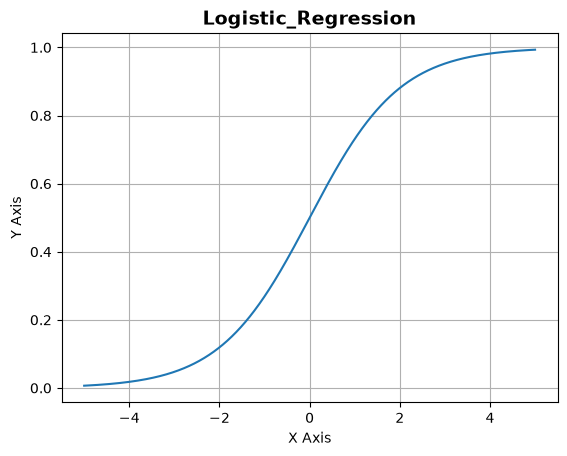

In [110]:
# Plot the sigmoid curve: large negative z -> ~0, large positive z -> ~1, z = 0 -> 0.5
x = np.linspace(-5, 5, 1000)
y = 1/(1 + np.exp(-x))
plt.plot(x, y)
plt.grid(True)
plt.title("Logistic_Regression", fontsize=14, fontweight='bold')
plt.xlabel("X Axis")
plt.ylabel("Y Axis")

## 3. Dataset

We implement the model on a dataset called `astronomical_objects`. It is a CSV file with 7209 rows and 11 columns (e.g. `brightness_u`, `surface_temperature`, `redshift`, ...). The label is 0 for stars and 1 for galaxies. The model we build here is logistic regression, one of the most widely used models for classification.

In [111]:
# Read the dataset using pandas (the CSV must be in the same folder as this notebook)
df = pd.read_csv("astronomical_objects.csv")

## 4. Data cleaning and exploration

In [112]:
# Shape of the dataset before processing: rows -> 7209, columns -> 11
df.shape

(7209, 11)

In [113]:
# Preview the first 5 rows: 10 numeric features + the label column
df.head()

,brightness_u,brightness_g,brightness_r,distance,color_index_ug,color_index_gr,spectral_type,surface_temperature,redshift,luminosity,label
0,0.568240,2.430918,-3.646546,-0.921678,-1.567053,NaN,1.687813,1810.200589,3.489883,-2.779161,0
1,-0.995100,2.081066,0.445951,0.194326,-2.300748,2.845045,-2.653903,436.475712,1.749606,1.149658,1
2,-1.537277,-2.473508,1.205040,-0.008393,0.498443,-0.794915,2.049318,-1774.881278,-0.013458,1.033887,1
3,-0.096099,2.007618,-1.295334,-1.534105,1.972705,0.416938,2.516700,391.930518,1.396267,-1.044353,0
4,-1.645211,-1.929394,-0.825050,0.653604,-2.757902,-0.449938,3.408010,-3085.730090,-2.175887,-1.980784,1


In [114]:
# Column types and non-null counts, used to spot missing (null) values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7209 entries, 0 to 7208
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brightness_u         7209 non-null   float64
 1   brightness_g         7209 non-null   float64
 2   brightness_r         6486 non-null   float64
 3   distance             7209 non-null   float64
 4   color_index_ug       7209 non-null   float64
 5   color_index_gr       6632 non-null   float64
 6   spectral_type        7209 non-null   float64
 7   surface_temperature  7209 non-null   float64
 8   redshift             6350 non-null   float64
 9   luminosity           7209 non-null   float64
 10  label                7209 non-null   int64  
dtypes: float64(10), int64(1)
memory usage: 619.7 KB


In [115]:
# Count fully duplicated rows
total_duplicates = df.duplicated().sum()
print(f"Total duplicate rows: {total_duplicates}")

Total duplicate rows: 210


**Findings:**
- Three columns contain missing values: `brightness_r` (723 missing), `color_index_gr` (577 missing) and `redshift` (859 missing).
- There are **210 duplicate rows**.

Both problems are handled by simply removing the affected rows.

In [116]:
# Remove rows with missing values, then remove duplicate rows
df = df.dropna()
df = df.drop_duplicates()

In [117]:
# Shape after removing nulls and duplicates (7209 -> 5111 rows)
df.shape

(5111, 11)

In [118]:
# Summary statistics (transposed so each feature is a row)
print(df.describe().T)

                      count        mean          std          min         25%  \
brightness_u         5111.0    0.009658     0.986287    -3.423800   -0.671550   
brightness_g         5111.0    0.793852     2.093118    -7.701560   -0.524352   
brightness_r         5111.0   -0.016675     2.183314    -7.523794   -1.619742   
distance             5111.0   -0.041567     3.041333   -39.727617   -0.670055   
color_index_ug       5111.0   -1.547760     1.653571    -9.164019   -2.657242   
color_index_gr       5111.0    0.021258     2.219362    -6.732443   -1.630543   
spectral_type        5111.0   -0.022682     2.025574    -7.315807   -1.516601   
surface_temperature  5111.0  768.357711  1937.082641 -7425.675715 -334.934751   
redshift             5111.0    0.753273     1.845587    -5.244653   -0.490748   
luminosity           5111.0    0.116502     7.038981   -91.488509   -1.467730   
label                5111.0    0.497554     0.500043     0.000000    0.000000   

                           

After removing nulls and duplicates we are left with **5111 rows** (about 29% of the original data was dropped).

What the summary statistics tell us:
- Most features have a standard deviation of roughly 1 to 3, but `surface_temperature` has a standard deviation of about 1,937 and values in the thousands. Such large values can cause overflow in `exp()` and slow down gradient descent, so **feature scaling is necessary**.
- The label mean is about 0.4976, so the two classes are almost perfectly **balanced** (about 50% stars, 50% galaxies). Accuracy is therefore a meaningful metric here.

## 5. Preprocessing

Steps in the next cell:
1. **Split:** a random 80/20 train/test split using a seeded NumPy permutation (`seed=0`) for reproducibility.
2. **Scale** the 10 original features (z-score), using the **training mean/std only** to avoid data leakage.
3. **Feature expansion:** add all squares and pairwise products of the features ($10 + 10 + 45 = 65$ features). Logistic regression is linear in its inputs, so these terms let the decision boundary be curved.
4. **Scale again**, since the new features have different ranges.
5. **Add the bias column** (a column of ones) last, so it is not scaled or expanded.

In [119]:
# Splitting and scaling the data

X = df.drop(columns="label").values          # 10 numeric features
y = df["label"].values.astype(float)         # target: 0 = star, 1 = galaxy

# 80/20 split using a seeded random permutation of the row indices
idx = np.random.default_rng(0).permutation(len(X)); cut = int(0.8 * len(X))
tr, te = idx[:cut], idx[cut:]

def scale(A_tr, A_te):                       # use TRAIN mean/std only
    m, s = A_tr.mean(0), A_tr.std(0); s[s == 0] = 1   # s == 0 guard avoids division by zero
    return (A_tr - m) / s, (A_te - m) / s

def expand(A):                               # original + all squares and pairwise products
    n = A.shape[1]
    return np.hstack([A] + [(A[:, i] * A[:, j])[:, None]
                            for i in range(n) for j in range(i, n)])

add_bias = lambda A: np.hstack([np.ones((len(A), 1)), A])   # prepend a column of ones (intercept)

Ztr, Zte = scale(X[tr], X[te])               # 1) scale the 10 original features
Xtr, Xte = scale(expand(Ztr), expand(Zte))   # 2) add squares/products, scale again
Xtr, Xte = add_bias(Xtr), add_bias(Xte)      # 3) add the bias column last

ytr = y[tr]
yte = y[te]

### Note: check the shapes

In [120]:
# Scaled + expanded training features (first column is the bias, all ones)
Xtr

array([[ 1.        , -0.5408271 , -0.31538057, ..., -0.77503121,
        -0.03115295, -0.09652788],
       [ 1.        , -0.29829146,  2.18231595, ..., -0.01128137,
         0.28782388, -0.08631961],
       [ 1.        ,  1.22858114,  0.89144127, ..., -0.49486545,
         0.08441046, -0.09479106],
       ...,
       [ 1.        , -0.76915449,  1.21560819, ..., -0.49633913,
         0.07776293, -0.09539449],
       [ 1.        , -0.39589355, -0.37841035, ..., -0.77641125,
        -0.05536235, -0.10170241],
       [ 1.        ,  1.13779537,  0.56822155, ...,  2.05983051,
        -0.01811028, -0.10182297]], shape=(4088, 66))

In [121]:
# Training labels (0 / 1)
ytr

array([1., 0., 0., ..., 1., 1., 1.], shape=(4088,))

In [122]:
# Expected: 66 columns = 1 bias + 10 original + 55 squares/products
print(f"Training set shape: {Xtr.shape}")
print(f"Testing set shape:  {Xte.shape}")

Training set shape: (4088, 66)
Testing set shape:  (1023, 66)


The dataset is now ready for training the model.

## 6. Model: logistic regression with gradient descent

For every sample the model computes the predicted probability $h = \sigma(X\theta)$ and minimizes the **binary cross-entropy (log-loss)** with an **L2 penalty**:

$$J(\theta) = -\frac{1}{m}\sum_{i=1}^{m}\Big[y_i \log h_i + (1-y_i)\log(1-h_i)\Big] + \frac{\lambda}{2m}\sum_{j\ge 1}\theta_j^2$$

The gradient is

$$\nabla J(\theta) = \frac{1}{m}X^T(h - y) + \frac{\lambda}{m}\theta \quad \text{(bias term not penalized)}$$

and each step updates $\theta \leftarrow \theta - \alpha \nabla J(\theta)$.

**Hyperparameters:** learning rate $\alpha = 0.5$, regularization $\lambda = 1.0$, 5001 iterations.

In [123]:
# Initialize the parameter vector with zeros, shape (66, 1): 1 bias + 65 feature weights
theta_mat = np.zeros(Xtr.shape[1]).astype(float).reshape(-1, 1)

In [124]:
# Bias and weights, size = (66, 1); all zeros before training
theta_mat

array([[0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.]])

In [125]:
theta_mat = np.zeros(Xtr.shape[1]).reshape(-1, 1)   # re-create theta as zeros (66, 1) so training always starts fresh

m = Xtr.shape[0]                                    # number of training samples (4088)
y = ytr.reshape(-1, 1)                              # labels as a column vector
lam = 1.0                                           # L2 strength

for i in range(5001):
    z = Xtr @ theta_mat                                         # linear scores
    sigma_z = 1/(1 + np.exp(-np.clip(z, -500, 500)))            # sigmoid -> probabilities (clip avoids overflow)
    error = sigma_z - y                                         # prediction error
    gradient = (1 / m) * (Xtr.T @ error)                        # gradient of the log-loss
    gradient[1:] += (lam / m) * theta_mat[1:]       # L2 penalty, skips the bias
    theta_mat -= 0.5 * gradient                     # learning rate 0.5

    if i % 100 == 0:
        # Log the training loss every 100 iterations (L2 term not included in the printed value)
        p = np.clip(sigma_z, 1e-12, 1 - 1e-12)
        loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
        print(f"iter {i:4d}  loss {loss:.4f}")

# Changing iter and learning rates might give better results

iter    0  loss 0.6931
iter  100  loss 0.1528
iter  200  loss 0.1385
iter  300  loss 0.1324
iter  400  loss 0.1288
iter  500  loss 0.1264
iter  600  loss 0.1246
iter  700  loss 0.1233
iter  800  loss 0.1223
iter  900  loss 0.1214
iter 1000  loss 0.1207
iter 1100  loss 0.1201
iter 1200  loss 0.1196
iter 1300  loss 0.1192
iter 1400  loss 0.1188
iter 1500  loss 0.1185
iter 1600  loss 0.1182
iter 1700  loss 0.1179
iter 1800  loss 0.1177
iter 1900  loss 0.1175
iter 2000  loss 0.1173
iter 2100  loss 0.1171
iter 2200  loss 0.1169
iter 2300  loss 0.1168
iter 2400  loss 0.1167
iter 2500  loss 0.1165
iter 2600  loss 0.1164
iter 2700  loss 0.1163
iter 2800  loss 0.1162
iter 2900  loss 0.1161
iter 3000  loss 0.1160
iter 3100  loss 0.1160
iter 3200  loss 0.1159
iter 3300  loss 0.1158
iter 3400  loss 0.1158
iter 3500  loss 0.1157
iter 3600  loss 0.1157
iter 3700  loss 0.1156
iter 3800  loss 0.1155
iter 3900  loss 0.1155
iter 4000  loss 0.1155
iter 4100  loss 0.1154
iter 4200  loss 0.1154
iter 4300  

### Training log

The loss starts at 0.6931 ($= \ln 2$), which is what a model predicting 0.5 for every sample gets. It drops quickly to about 0.153 in the first 100 iterations and then flattens out at about **0.115**. After roughly 3000 iterations the improvement is tiny, so extra iterations give almost no benefit.

## 7. Evaluation

The metrics are computed manually from the confusion matrix on the **unseen test set**, using a 0.5 probability threshold:

| Metric | Formula | Meaning |
|---|---|---|
| Accuracy | $(TP+TN)/N$ | share of all predictions that are correct |
| Precision | $TP/(TP+FP)$ | of objects predicted galaxy, how many really are |
| Recall | $TP/(TP+FN)$ | of real galaxies, how many were found |
| F1 | $2PR/(P+R)$ | harmonic mean of precision and recall |
| Log-loss | cross-entropy | quality of the predicted probabilities (lower is better) |

In [126]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

y_t = yte.ravel().astype(int)                       # true test labels
p_test = sigmoid(Xte @ theta_mat).ravel()          # fresh probabilities
y_hat = (p_test >= 0.5).astype(int)                # hard predictions with a 0.5 threshold

# Confusion matrix entries (galaxy = positive class)
TP = np.sum((y_t == 1) & (y_hat == 1))
FP = np.sum((y_t == 0) & (y_hat == 1))
FN = np.sum((y_t == 1) & (y_hat == 0))
TN = np.sum((y_t == 0) & (y_hat == 0))

# Metrics (the `if` guards avoid division by zero)
accuracy  = (TP + TN) / len(y_t)
precision = TP / (TP + FP) if TP + FP else 0
recall    = TP / (TP + FN) if TP + FN else 0
f1        = 2 * precision * recall / (precision + recall) if precision + recall else 0
logloss   = -np.mean(y_t * np.log(np.clip(p_test, 1e-12, 1)) +
                     (1 - y_t) * np.log(np.clip(1 - p_test, 1e-12, 1)))

print("Confusion matrix [[TN FP], [FN TP]]:\n", np.array([[TN, FP], [FN, TP]]))
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 score : {f1:.4f}")
print(f"Log-loss : {logloss:.4f}")

Confusion matrix [[TN FP], [FN TP]]:
 [[503  25]
 [ 19 476]]
Accuracy : 0.9570
Precision: 0.9501
Recall   : 0.9616
F1 score : 0.9558
Log-loss : 0.1673


### Results

| | Predicted star | Predicted galaxy |
|---|---|---|
| **Actual star** | 503 (TN) | 25 (FP) |
| **Actual galaxy** | 19 (FN) | 476 (TP) |

| Metric | Test score |
|---|---|
| Accuracy | 0.9570 |
| Precision | 0.9501 |
| Recall | 0.9616 |
| F1 score | 0.9558 |
| Log-loss | 0.1673 |

The model gets 979 of the 1023 test samples right. Errors are balanced between the two classes (25 stars mistaken for galaxies, 19 galaxies missed).

## 8. Conclusions and next steps

Logistic regression with polynomial features reaches about **95.7% test accuracy** on this dataset.

The final training loss (about 0.115) is lower than the test log-loss (0.167). This gap suggests **mild overfitting**, which is expected with 65 expanded features and only 4088 training samples.

**Ideas to improve:**
- Tune `lam` (L2 strength), the learning rate and the number of iterations on a separate validation set or with k-fold cross-validation
- Try polynomial degrees other than 2, or only a subset of the interaction terms
- Impute missing values instead of dropping them (about 29% of the data was removed)
- Tune the decision threshold, or add ROC-AUC and a ROC curve to the evaluation
- Plot the loss curve instead of printing it, and add early stopping
- Compare with `sklearn.linear_model.LogisticRegression` as a sanity check